# ASL Citizen -- 1000 classes -- Video Swin Transformer (Swin3D-T), RGB stream
### Capstone C -- model comparison track (new architecture #1 of 2)

**What this trains:** `torchvision.models.video.swin3d_t`, Kinetics-400 pretrained, fine-tuned
end-to-end on the **cached RGB `appearance` crops** of the ASL Citizen top-1000 classes.

**Why it is in the comparison:** Capstone B's RGB model was `r3d_18` (3D CNN), which overfit badly
(1000-class dual-stream test top-1 = 0.282). Video Swin is the transformer counterpart: shifted-window
self-attention over space *and* time instead of 3x3x3 convolutions. This run answers
*"is the RGB-stream failure specific to the 3D-CNN, or does a modern video transformer hit the
same data ceiling (~15 training clips per class)?"* -- a valid result either way.

**Fair comparison:** same cache, same manifest code, same top-1000 class mapping, same
signer-independent train/val/test split, same `WeightedRandomSampler`, early stopping on `val_top1`,
test set touched once at the end -- identical protocol to the v10 notebooks.

---
### How to run on Kaggle (one-time setup, ~3 min)
1. **Create** -> New Notebook -> *File -> Import Notebook* -> upload this `.ipynb`.
2. **Add Input** (right panel) -- the same inputs as the v10 notebooks:
   - notebook outputs `asl-shared-cache-building-id00`, `-id01`, `-id02` (the 3 cache shards)
   - dataset `asl-citizen` (for `splits/`)
   Paths are auto-discovered if they differ from `CONFIG` below.
3. **Settings:** Accelerator = **GPU T4 x2**, Internet = **On** (downloads Kinetics-400 weights, ~120 MB).
4. *(Recommended)* set `SMOKE_TEST = True`, click **Run All** interactively, confirm it finishes
   (~5-10 min), then set it back to `False`.
5. **Save Version -> Save & Run All (Commit)** -- runs in the background, you can close the tab.
6. When done: **Output** tab -> download `swin3d_t_1000cls/app_export/` (+ the metrics files).

**Time budget:** estimated **3-5 h** on T4 x2 (printed live after the first ~100 steps).
A guard stops training before Kaggle's 12 h limit and still runs the test evaluation.
If a run is ever cut off: attach this notebook's previous version output as an input and set
`RESUME_FROM` to its `last.pt`.

## 1. Setup

In [1]:
import csv
import glob
import hashlib
import json
import math
import os
import random
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

NOTEBOOK_START = time.time()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_GPUS = torch.cuda.device_count()


def _env(name, default):
    # Environment overrides exist ONLY for the local CPU smoke test of this notebook.
    # On Kaggle none of these are set, so the defaults in CONFIG below are what run.
    return os.environ.get(name, default)


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


print(f"Torch {torch.__version__} | device={DEVICE} | GPUs={N_GPUS}")
for i in range(N_GPUS):
    print(f"  cuda:{i} -> {torch.cuda.get_device_name(i)}")

import torchvision
from torchvision.models.video import swin3d_t, Swin3D_T_Weights
from torchvision.ops import StochasticDepth
print(f"torchvision {torchvision.__version__}")

Torch 2.10.0+cu128 | device=cuda | GPUs=2
  cuda:0 -> Tesla T4
  cuda:1 -> Tesla T4
torchvision 0.25.0+cu128


## 2. Configuration
Hyperparameters were chosen for a 28M-parameter pretrained transformer on ~15 clips/class:
low backbone LR, higher head LR, warm-up + cosine, strong regularisation (stochastic depth 0.2,
head dropout 0.5, weight decay 0.05, label smoothing 0.1). Mixed precision (fp16) is ON here for
speed; the NaN guard + `GradScaler` handle the instability that made v9.1 turn AMP off.

In [2]:
class CONFIG:
    WORK_DIR = Path(_env("ASL_WORK_DIR", "/kaggle/working"))

    # ---- inputs (same as the v10 notebooks; auto-discovered if these paths don't exist) ----
    CACHE_DIRS = [
        Path("/kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0"),
        Path("/kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2"),
        Path("/kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1"),
    ]
    SPLITS_DIR = Path("/kaggle/input/datasets/pranaysahaps/asl-citizen/splits")
    OUT_DIR = WORK_DIR / "swin3d_t_1000cls"

    TOP_K_CLASSES = int(_env("ASL_TOP_K", 1000))
    FRAME_COUNT = 16                     # cache extraction config (v10 CONFIG.FRAME_COUNT)
    APPEARANCE_STREAM = 0                # appearance[t, 0] = signer crop (as in v10 Section 11)

    # ---- model input (torchvision Kinetics-400 video preset) ----
    IMG_SIZE = int(_env("ASL_IMG_SIZE", 224))   # env override = local CPU smoke test only
    MEAN = (0.43216, 0.394666, 0.37645)
    STD = (0.22803, 0.22145, 0.216989)
    PRETRAINED = _env("ASL_PRETRAINED", "1") == "1"

    # ---- regularisation / augmentation ----
    STOCHASTIC_DEPTH = 0.2
    HEAD_DROPOUT = 0.5
    AUG_SCALE_MIN = 0.80                 # random-resized-crop area range [0.8, 1.0], same crop for all frames
    AUG_HFLIP = False                    # mirroring swaps the dominant hand -- off, matches prior runs

    # ---- optimisation ----
    BATCH_SIZE = int(_env("ASL_BATCH", 16))   # total across GPUs (8 per T4)
    NUM_WORKERS = int(_env("ASL_NUM_WORKERS", 4))
    EPOCHS = int(_env("ASL_EPOCHS", 25))
    WARMUP_EPOCHS = 1
    LR_BACKBONE = 5e-5
    LR_HEAD = 1e-3
    WEIGHT_DECAY = 0.05
    LABEL_SMOOTHING = 0.1
    GRAD_CLIP_NORM = 1.0
    USE_AMP = True

    # ---- early stopping on val_top1 (same rule as v10) ----
    MIN_EPOCHS_BEFORE_STOPPING = 10
    EARLY_STOPPING_PATIENCE = 5

    # ---- Kaggle session safety ----
    TIME_BUDGET_HOURS = float(_env("ASL_TIME_BUDGET_H", 11.0))   # Kaggle hard limit is 12 h
    RESUME_FROM = None                   # e.g. Path("/kaggle/input/<prev-version>/swin3d_t_1000cls/last.pt")

    # ---- smoke test: tiny subset, 1 epoch -- verifies the whole pipeline in minutes ----
    SMOKE_TEST = _env("ASL_SMOKE_TEST", "0") == "1"
    SMOKE_SAMPLES = {"train": 256, "val": 128, "test": 128}

    SEED = 42


if CONFIG.SMOKE_TEST:
    CONFIG.EPOCHS = 1
    CONFIG.MIN_EPOCHS_BEFORE_STOPPING = 1


def resolve_inputs():
    """Use CONFIG paths if they exist; otherwise auto-discover the cache shards / splits
    under /kaggle/input (Kaggle mount paths change depending on how inputs are attached)."""
    env_cache = os.environ.get("ASL_CACHE_DIRS")
    if env_cache:
        CONFIG.CACHE_DIRS = [Path(p) for p in env_cache.split(os.pathsep)]
    env_splits = os.environ.get("ASL_SPLITS_DIR")
    if env_splits:
        CONFIG.SPLITS_DIR = Path(env_splits)

    if not all(p.exists() for p in CONFIG.CACHE_DIRS):
        found = sorted({Path(p) for p in glob.glob("/kaggle/input/**/feature_cache_shard_*", recursive=True)
                        if Path(p).is_dir()})
        print(f"[inputs] configured CACHE_DIRS not all present -- auto-discovered {len(found)} shard dirs:")
        for p in found:
            print("   ", p)
        CONFIG.CACHE_DIRS = found
    assert CONFIG.CACHE_DIRS, ("No feature_cache_shard_* directories found. Attach the three "
                               "asl-shared-cache-building notebooks' outputs as inputs (see top of notebook).")
    if len(CONFIG.CACHE_DIRS) != 3:
        print(f"[inputs] WARNING: expected 3 cache shards (as in the v10 notebooks), found "
              f"{len(CONFIG.CACHE_DIRS)}. The class subset may differ from the v10 runs.")

    if not (CONFIG.SPLITS_DIR / "train.csv").exists():
        hits = sorted(glob.glob("/kaggle/input/**/splits/train.csv", recursive=True))
        assert hits, "ASL Citizen splits/train.csv not found -- attach the asl-citizen dataset."
        CONFIG.SPLITS_DIR = Path(hits[0]).parent
        print(f"[inputs] auto-discovered SPLITS_DIR: {CONFIG.SPLITS_DIR}")
    print("Cache shards:", *CONFIG.CACHE_DIRS, sep="\n   ")
    print("Splits dir:  ", CONFIG.SPLITS_DIR)


resolve_inputs()
seed_everything(CONFIG.SEED)
CONFIG.OUT_DIR.mkdir(parents=True, exist_ok=True)

Cache shards:
   /kaggle/input/notebooks/aniruddha2022/asl-shared-cache-building-id00/feature_cache_shard_0
   /kaggle/input/notebooks/redoanmozumder/asl-shared-cache-building-id02/feature_cache_shard_2
   /kaggle/input/notebooks/pranaysahaps/asl-shared-cache-building-id01/feature_cache_shard_1
Splits dir:   /kaggle/input/datasets/pranaysahaps/asl-citizen/splits


## Build the manifest & apply the Top-1000 class filter

**Copied verbatim** from the team's v10 notebook (Section 3): rebuild the label space from the
official ASL Citizen `train.csv` / `val.csv` / `test.csv`, restricted to videos present in the
cache, then keep the `TOP_K_CLASSES` most-represented classes (remapped to `0..K-1`, most
represented = index 0). Same code + same cache = same 1000 classes and same index mapping as the
team's other 1000-class runs, so every model in the comparison is evaluated on the identical
signer-independent test split.

The class list is saved to `class_list.json` with a fingerprint -- both notebooks print it, and
**the fingerprints must match** for the comparison to be valid.

In [3]:
cache_index = {}
for shard_dir in CONFIG.CACHE_DIRS:
    assert shard_dir.exists(), f"Cache shard not found: {shard_dir} -- update CONFIG.CACHE_DIRS"
    for f in shard_dir.glob("*.npz"):
        cache_index[f.stem] = f
print(f"Total cached .npz files across {len(CONFIG.CACHE_DIRS)} shards: {len(cache_index)}")

split_files = {
    "train": CONFIG.SPLITS_DIR / "train.csv",
    "val": CONFIG.SPLITS_DIR / "val.csv",
    "test": CONFIG.SPLITS_DIR / "test.csv",
}
rows, all_glosses = [], set()
for subset, csv_path in split_files.items():
    assert csv_path.exists(), f"Missing split file: {csv_path}"
    with open(csv_path, newline="", encoding="utf-8") as f:
        reader = csv.DictReader(f)
        for row in reader:
            video_id = Path(row["Video file"]).stem
            gloss = row["Gloss"]
            all_glosses.add(gloss)
            if video_id in cache_index:
                rows.append((video_id, gloss, subset))

class_list_full = sorted(all_glosses)
class_to_idx_full = {g: i for i, g in enumerate(class_list_full)}

nslt_data_full = {}
for video_id, gloss, subset in rows:
    nslt_data_full[video_id] = {"action": [class_to_idx_full[gloss], 0, 0], "subset": subset}

print(f"Cached rows matched against splits: {len(rows)}")
print(f"Full ASL Citizen vocabulary present in cache: {len(class_list_full)} classes")

# --- top-K filter, identical remap logic to the v10 notebooks ---
class_video_counts = Counter(v["action"][0] for v in nslt_data_full.values())
top_k_old_indices = [c for c, _ in class_video_counts.most_common(CONFIG.TOP_K_CLASSES)]
top_k_old_indices_set = set(top_k_old_indices)
old_to_new_idx = {old_idx: new_idx for new_idx, old_idx in enumerate(top_k_old_indices)}

nslt_data = {
    vid: {"action": [old_to_new_idx[meta["action"][0]], 0, 0], "subset": meta["subset"]}
    for vid, meta in nslt_data_full.items()
    if meta["action"][0] in top_k_old_indices_set
}
class_list = {old_to_new_idx[old]: class_list_full[old] for old in top_k_old_indices}
NUM_CLASSES = len(class_list)

subset_counts = Counter(v["subset"] for v in nslt_data.values())
print(f"\nTop-{CONFIG.TOP_K_CLASSES} filter applied -- NUM_CLASSES: {NUM_CLASSES}")
print(f"Videos remaining: {len(nslt_data)} across splits {dict(subset_counts)}")

per_class_counts = Counter(v["action"][0] for v in nslt_data.values())
print(f"Videos/class (post-filter, all splits combined): "
      f"min={min(per_class_counts.values())} median={int(np.median(list(per_class_counts.values())))} "
      f"max={max(per_class_counts.values())}")

# --- added: persist the exact class mapping for the web app + cross-notebook check ---
CLASS_NAMES = [class_list[i] for i in range(NUM_CLASSES)]
CLASS_FINGERPRINT = hashlib.sha1("\n".join(CLASS_NAMES).encode("utf-8")).hexdigest()[:12]
with open(CONFIG.OUT_DIR / "class_list.json", "w", encoding="utf-8") as f:
    json.dump({"num_classes": NUM_CLASSES, "fingerprint": CLASS_FINGERPRINT,
               "rule": f"ASL Citizen top-{CONFIG.TOP_K_CLASSES} most-represented glosses in cache "
                       f"(Counter.most_common), index 0 = most represented",
               "classes": CLASS_NAMES}, f, indent=1)
print(f"\nClass-list fingerprint: {CLASS_FINGERPRINT}   (must match across all 1000-class notebooks)")


def split_samples(subset):
    # Same sample construction (and order) as the v10 WLASLCachedDataset.
    s = [(vid, meta["action"][0]) for vid, meta in nslt_data.items()
         if meta["subset"] == subset and vid in cache_index]
    if CONFIG.SMOKE_TEST:
        rng = random.Random(0)
        s = rng.sample(s, min(len(s), CONFIG.SMOKE_SAMPLES[subset]))
    return s


train_samples, val_samples, test_samples = (split_samples(s) for s in ("train", "val", "test"))
print(f"Train / val / test samples: {len(train_samples)} / {len(val_samples)} / {len(test_samples)}"
      + ("   [SMOKE TEST SUBSET]" if CONFIG.SMOKE_TEST else ""))

Total cached .npz files across 3 shards: 63550
Cached rows matched against splits: 63550
Full ASL Citizen vocabulary present in cache: 2731 classes

Top-1000 filter applied -- NUM_CLASSES: 1000
Videos remaining: 30909 across splits {'train': 14571, 'val': 3778, 'test': 12560}
Videos/class (post-filter, all splits combined): min=30 median=31 max=32

Class-list fingerprint: 72d3ef78291c   (must match across all 1000-class notebooks)
Train / val / test samples: 14571 / 3778 / 12560


## 3. Inspect the cached `appearance` tensor
The v10 notebook only shows that `appearance[t, 0]` is a displayable frame. Rather than assume the
crop size / dtype / value range, this cell **measures** them from the cache and fails loudly if the
data is not raw pixel values. A sample strip is saved to `appearance_probe.png` -- glance at it to
confirm colours look natural (if faces look blue, the cache stored BGR: set the flag below and re-run).

npz keys: {'appearance': ((16, 1, 112, 112, 3), 'uint8'), 'landmarks': ((16, 116), 'float32')}
appearance shapes: {(16, 1, 112, 112, 3)} | dtype: uint8 | value range: [0.000, 255.000]
-> pixel scale factor to uint8: 1.0
normalised clip: (16, 112, 112, 3) uint8 (T, H, W, C); native crop size (112, 112) -> resized to 224x224 on GPU


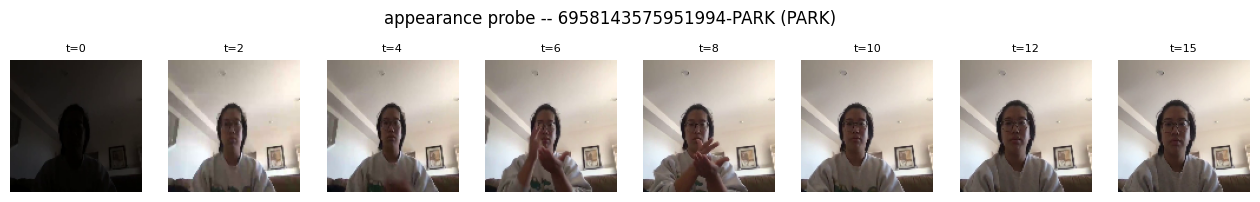

In [4]:
APPEARANCE_IS_BGR = False   # flip to True only if appearance_probe.png shows swapped colours

probe_ids = [vid for vid, _ in train_samples[:12]]
with np.load(cache_index[probe_ids[0]]) as d:
    print("npz keys:", {k: (d[k].shape, str(d[k].dtype)) for k in d.files})

probe = []
for vid in probe_ids:
    with np.load(cache_index[vid]) as d:
        probe.append(np.asarray(d["appearance"]))
shapes = {p.shape for p in probe}
vmin = float(min(p.min() for p in probe)); vmax = float(max(p.max() for p in probe))
print(f"appearance shapes: {shapes} | dtype: {probe[0].dtype} | value range: [{vmin:.3f}, {vmax:.3f}]")

assert vmin >= -1e-3, ("appearance contains negative values -> it was stored already normalised with "
                       "unknown statistics. Stop and check the cache-building notebook before training.")
VALUE_SCALE = 255.0 if vmax <= 1.0 + 1e-3 else 1.0
print(f"-> pixel scale factor to uint8: {VALUE_SCALE}")


def appearance_to_thwc(a):
    """Cached appearance array -> uint8 (T, H, W, 3), temporal order preserved."""
    a = np.asarray(a)
    if a.ndim == 5:                       # (T, S, H, W, C)
        a = a[:, CONFIG.APPEARANCE_STREAM]
    if a.ndim != 4:
        raise ValueError(f"unexpected appearance ndim {a.ndim}: {a.shape}")
    if a.shape[-1] != 3 and a.shape[1] == 3:   # (T, C, H, W) -> (T, H, W, C)
        a = a.transpose(0, 2, 3, 1)
    if a.shape[-1] != 3:
        raise ValueError(f"cannot find RGB channel axis in {a.shape}")
    if a.shape[0] != CONFIG.FRAME_COUNT:  # uniform resample (only if cache differs from config)
        a = a[np.linspace(0, a.shape[0] - 1, CONFIG.FRAME_COUNT).round().astype(int)]
    if a.dtype != np.uint8:
        a = np.clip(a.astype(np.float32) * VALUE_SCALE, 0, 255).astype(np.uint8)
    if APPEARANCE_IS_BGR:
        a = a[..., ::-1]
    return np.ascontiguousarray(a)


ref = appearance_to_thwc(probe[0])
REF_HW = ref.shape[1:3]
print(f"normalised clip: {ref.shape} uint8 (T, H, W, C); native crop size {REF_HW} -> resized to "
      f"{CONFIG.IMG_SIZE}x{CONFIG.IMG_SIZE} on GPU")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, t in zip(axes, np.linspace(0, CONFIG.FRAME_COUNT - 1, 8).astype(int)):
    ax.imshow(ref[t]); ax.set_title(f"t={t}", fontsize=8); ax.axis("off")
plt.suptitle(f"appearance probe -- {probe_ids[0]} ({CLASS_NAMES[train_samples[0][1]]})")
plt.savefig(CONFIG.OUT_DIR / "appearance_probe.png", dpi=100, bbox_inches="tight"); plt.show()
del probe

## 4. Dataset & loaders
Workers only decode the `.npz` and return raw `uint8` clips; resizing, augmentation and
normalisation run batched **on the GPU** so the 4 Kaggle CPU cores don't bottleneck two T4s.

In [5]:
class AppearanceDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        vid, label = self.samples[i]
        with np.load(cache_index[vid]) as d:
            clip = appearance_to_thwc(d["appearance"])
        clip = torch.from_numpy(clip)
        if tuple(clip.shape[1:3]) != tuple(REF_HW):   # defensive: keep batch shapes equal
            clip = F.interpolate(clip.permute(0, 3, 1, 2).float(), size=REF_HW, mode="bilinear",
                                 align_corners=False).round().clamp(0, 255).byte().permute(0, 2, 3, 1)
        return clip, label


def make_loader(samples, train):
    ds = AppearanceDataset(samples)
    kw = dict(batch_size=CONFIG.BATCH_SIZE, num_workers=CONFIG.NUM_WORKERS,
              pin_memory=DEVICE == "cuda", persistent_workers=CONFIG.NUM_WORKERS > 0)
    if CONFIG.NUM_WORKERS > 0:
        kw["prefetch_factor"] = 4
    if train:
        counts = Counter(c for _, c in samples)
        weights = [1.0 / counts[c] for _, c in samples]   # same class balancing as v10
        sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=False, **kw)


train_loader = make_loader(train_samples, train=True)
val_loader = make_loader(val_samples, train=False)
test_loader = make_loader(test_samples, train=False)

_MEAN = torch.tensor(CONFIG.MEAN, device=DEVICE).view(1, 3, 1, 1, 1)
_STD = torch.tensor(CONFIG.STD, device=DEVICE).view(1, 3, 1, 1, 1)


def gpu_preprocess(x, train):
    """uint8 (B, T, H, W, 3) -> normalised float (B, 3, T, S, S).
    Eval / app inference: full-frame resize to S x S, no crop."""
    x = x.permute(0, 4, 1, 2, 3).float().div_(255.0)          # (B, 3, T, H, W)
    B, _, T, H, W = x.shape
    S = CONFIG.IMG_SIZE
    if train:
        out = []
        for i in range(B):
            area = random.uniform(CONFIG.AUG_SCALE_MIN, 1.0)
            ch, cw = max(8, int(H * math.sqrt(area))), max(8, int(W * math.sqrt(area)))
            y0, x0 = random.randint(0, H - ch), random.randint(0, W - cw)
            c = x[i:i + 1, :, :, y0:y0 + ch, x0:x0 + cw]
            if CONFIG.AUG_HFLIP and random.random() < 0.5:
                c = c.flip(-1)
            out.append(F.interpolate(c, size=(T, S, S), mode="trilinear", align_corners=False))
        x = torch.cat(out)
    else:
        x = F.interpolate(x, size=(T, S, S), mode="trilinear", align_corners=False)
    return (x - _MEAN) / _STD


xb, yb = next(iter(val_loader))
print("raw batch:", tuple(xb.shape), xb.dtype, "| model input:", tuple(gpu_preprocess(xb.to(DEVICE), False).shape))

raw batch: (16, 16, 112, 112, 3) torch.uint8 | model input: (16, 3, 16, 224, 224)


## 5. Model -- Swin3D-T with a new 1000-way head
`head` (768 -> 400 Kinetics classes) is replaced by `Dropout(0.5) -> Linear(768, 1000)`. Every
other weight starts from Kinetics-400 and is fine-tuned. Stochastic depth is raised from
torchvision's default 0.1 to 0.2 (scaled per block, keeping torchvision's linear schedule).

In [6]:
def build_model(num_classes, pretrained):
    weights = Swin3D_T_Weights.KINETICS400_V1 if pretrained else None
    m = swin3d_t(weights=weights)
    for mod in m.modules():                 # 0.1 -> STOCHASTIC_DEPTH, same per-block schedule
        if isinstance(mod, StochasticDepth):
            mod.p = mod.p * (CONFIG.STOCHASTIC_DEPTH / 0.1)
    m.head = nn.Sequential(nn.Dropout(CONFIG.HEAD_DROPOUT), nn.Linear(m.head.in_features, num_classes))
    return m


seed_everything(CONFIG.SEED)
base_model = build_model(NUM_CLASSES, CONFIG.PRETRAINED).to(DEVICE)
model = nn.DataParallel(base_model) if N_GPUS > 1 else base_model
n_params = sum(p.numel() for p in base_model.parameters())
print(f"Swin3D-T parameters: {n_params:,}  | pretrained={CONFIG.PRETRAINED} | DataParallel={N_GPUS > 1}")

head_params = list(base_model.head.parameters())
head_ids = {id(p) for p in head_params}
decay, no_decay = [], []
for n_, p in base_model.named_parameters():
    if id(p) in head_ids:
        continue
    (no_decay if p.ndim <= 1 or "relative_position_bias_table" in n_ else decay).append(p)
optimizer = torch.optim.AdamW([
    {"params": decay, "lr": CONFIG.LR_BACKBONE, "weight_decay": CONFIG.WEIGHT_DECAY},
    {"params": no_decay, "lr": CONFIG.LR_BACKBONE, "weight_decay": 0.0},
    {"params": head_params, "lr": CONFIG.LR_HEAD, "weight_decay": CONFIG.WEIGHT_DECAY},
])
steps_per_epoch = len(train_loader)
total_steps = max(1, CONFIG.EPOCHS * steps_per_epoch)
warmup_steps = min(CONFIG.WARMUP_EPOCHS * steps_per_epoch, total_steps // 2)


def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / max(1, warmup_steps)
    prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG.LABEL_SMOOTHING)
amp_on = CONFIG.USE_AMP and DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_on)
print(f"steps/epoch={steps_per_epoch} | total={total_steps} | warmup={warmup_steps} | AMP={amp_on}")

Downloading: "https://download.pytorch.org/models/swin3d_t-7615ae03.pth" to /root/.cache/torch/hub/checkpoints/swin3d_t-7615ae03.pth


100%|██████████| 122M/122M [00:00<00:00, 170MB/s]


Swin3D-T parameters: 28,619,470  | pretrained=True | DataParallel=True
steps/epoch=910 | total=22750 | warmup=910 | AMP=True


## 6. Training (resumable, NaN-guarded, time-boxed)
Same hygiene as v9.1/v10: per-epoch `last.pt`, `best_model.pt` selected on **val top-1**, early
stopping after `MIN_EPOCHS_BEFORE_STOPPING` with `EARLY_STOPPING_PATIENCE`, NaN rollback.
Added: a time guard that will not start an epoch it cannot finish (plus a reserve for the
test evaluation) inside `TIME_BUDGET_HOURS`.

In [7]:
def model_has_nan(m):
    return any(not torch.isfinite(p).all() for p in m.parameters())


def topk_correct(logits, y, k):
    k = min(k, logits.shape[1])
    return logits.topk(k, dim=1).indices.eq(y.unsqueeze(1)).any(dim=1).sum().item()


def run_epoch(loader, train, epoch=None):
    model.train(train)
    tot_loss, c1, c5, n, skipped = 0.0, 0, 0, 0, 0
    t0 = time.time()
    with torch.set_grad_enabled(train):
        for step, (x, y) in enumerate(loader):
            x = gpu_preprocess(x.to(DEVICE, non_blocking=True), train)
            y = y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on):
                logits = model(x)
            loss = criterion(logits.float(), y)
            if not torch.isfinite(loss):
                skipped += 1
                continue
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                gn = torch.nn.utils.clip_grad_norm_(base_model.parameters(), CONFIG.GRAD_CLIP_NORM)
                if torch.isfinite(gn):
                    scaler.step(optimizer)
                else:
                    skipped += 1
                scaler.update()
                scheduler.step()
            bs = y.size(0)
            tot_loss += loss.item() * bs; c1 += topk_correct(logits, y, 1); c5 += topk_correct(logits, y, 5); n += bs
            if train and step in (50, 200) or (train and step > 0 and step % 500 == 0):
                rate = n / (time.time() - t0)
                print(f"   epoch {epoch} step {step}/{len(loader)} | {rate:.1f} clips/s | "
                      f"epoch ETA {(len(loader.sampler) - n) / max(rate, 1e-6) / 60:.1f} min | "
                      f"loss {tot_loss / n:.3f}")
    if skipped:
        print(f"   [warning] {skipped} non-finite batches skipped")
    return {"loss": tot_loss / max(n, 1), "top1": c1 / max(n, 1), "top5": c5 / max(n, 1),
            "seconds": time.time() - t0}


LAST_PATH = CONFIG.OUT_DIR / "last.pt"
BEST_PATH = CONFIG.OUT_DIR / "best_model.pt"
history, best_val_top1, epochs_without_improvement, start_epoch = [], -1.0, 0, 1

resume_path = CONFIG.RESUME_FROM if CONFIG.RESUME_FROM else (LAST_PATH if LAST_PATH.exists() else None)
if resume_path is not None and Path(resume_path).exists():
    st = torch.load(resume_path, map_location=DEVICE, weights_only=False)
    base_model.load_state_dict(st["model_state_dict"])
    optimizer.load_state_dict(st["optimizer_state_dict"])
    scheduler.load_state_dict(st["scheduler_state_dict"])
    scaler.load_state_dict(st["scaler_state_dict"])
    history, best_val_top1 = st["history"], st["best_val_top1"]
    epochs_without_improvement, start_epoch = st["epochs_without_improvement"], st["epoch"] + 1
    prev_best = Path(resume_path).parent / "best_model.pt"
    if prev_best.exists() and prev_best.resolve() != BEST_PATH.resolve():
        BEST_PATH.write_bytes(prev_best.read_bytes())   # carry the previous version's best forward
    print(f"Resumed from {resume_path}: continuing at epoch {start_epoch}, best val_top1 {best_val_top1:.3f}")
else:
    print("Starting fresh.")

budget_s = CONFIG.TIME_BUDGET_HOURS * 3600
test_reserve_s = 15 * 60
best_epoch = max((h["epoch"] for h in history if h["val_top1"] >= best_val_top1), default=0)

for epoch in range(start_epoch, CONFIG.EPOCHS + 1):
    elapsed = time.time() - NOTEBOOK_START
    if history:
        per_epoch = max(h["epoch_seconds"] for h in history[-3:])
        if elapsed + per_epoch * 1.1 + test_reserve_s > budget_s:
            print(f"[time guard] {elapsed / 3600:.2f} h used; next epoch (~{per_epoch / 60:.0f} min) + test "
                  f"evaluation would exceed {CONFIG.TIME_BUDGET_HOURS} h -- stopping training here.")
            break

    tr = run_epoch(train_loader, True, epoch)
    va = run_epoch(val_loader, False)
    test_reserve_s = va["seconds"] * max(1.0, len(test_samples) / max(1, len(val_samples))) * 1.5 + 10 * 60

    if model_has_nan(base_model):
        print(f"[STOPPING] epoch {epoch} produced NaN weights; best_model.pt (val_top1={best_val_top1:.3f}) is intact.")
        break

    rec = {"epoch": epoch, "train_loss": tr["loss"], "train_top1": tr["top1"], "train_top5": tr["top5"],
           "val_loss": va["loss"], "val_top1": va["top1"], "val_top5": va["top5"],
           "epoch_seconds": tr["seconds"] + va["seconds"], "lr_head": optimizer.param_groups[2]["lr"]}
    history.append(rec)
    print(f"Epoch {epoch}/{CONFIG.EPOCHS} | train loss {tr['loss']:.4f} top1 {tr['top1']:.3f} | "
          f"val loss {va['loss']:.4f} top1 {va['top1']:.3f} top5 {va['top5']:.3f} | "
          f"{rec['epoch_seconds'] / 60:.1f} min | total {(time.time() - NOTEBOOK_START) / 3600:.2f} h")

    is_best = va["top1"] > best_val_top1
    if is_best:
        best_val_top1, best_epoch, epochs_without_improvement = va["top1"], epoch, 0
        torch.save({"epoch": epoch, "model_state_dict": base_model.state_dict(),
                    "val_top1": best_val_top1, "val_loss": va["loss"]}, BEST_PATH)
        print(f"   -> new best val_top1 {best_val_top1:.3f}, saved best_model.pt")
    else:
        epochs_without_improvement += 1

    torch.save({"epoch": epoch, "model_state_dict": base_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(), "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(), "history": history, "best_val_top1": best_val_top1,
                "best_epoch": best_epoch, "epochs_without_improvement": epochs_without_improvement}, LAST_PATH)
    with open(CONFIG.OUT_DIR / "training_history.json", "w") as f:
        json.dump(history, f, indent=1)

    if (not is_best and epoch >= CONFIG.MIN_EPOCHS_BEFORE_STOPPING
            and epochs_without_improvement >= CONFIG.EARLY_STOPPING_PATIENCE):
        print(f"Early stopping at epoch {epoch}: no val_top1 improvement for {CONFIG.EARLY_STOPPING_PATIENCE} epochs.")
        break

best = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False)
base_model.load_state_dict(best["model_state_dict"])
print(f"\nTraining done in {(time.time() - NOTEBOOK_START) / 3600:.2f} h. "
      f"Restored best epoch {best['epoch']} (val_top1 {best['val_top1']:.3f}).")
plot_history(history, "Swin3D-T (1000 cls)", CONFIG.OUT_DIR / "training_curves.png")

Starting fresh.
   epoch 1 step 50/910 | 18.3 clips/s | epoch ETA 12.5 min | loss 6.953
   epoch 1 step 200/910 | 19.4 clips/s | epoch ETA 9.7 min | loss 6.945
   epoch 1 step 500/910 | 19.2 clips/s | epoch ETA 5.7 min | loss 6.908
   [warning] 2 non-finite batches skipped
Epoch 1/25 | train loss 6.5893 top1 0.018 | val loss 5.4432 top1 0.077 top5 0.214 | 14.4 min | total 0.24 h
   -> new best val_top1 0.077, saved best_model.pt
   epoch 2 step 50/910 | 18.2 clips/s | epoch ETA 12.6 min | loss 5.531
   epoch 2 step 200/910 | 18.4 clips/s | epoch ETA 10.3 min | loss 5.352
   epoch 2 step 500/910 | 18.4 clips/s | epoch ETA 5.9 min | loss 4.991
Epoch 2/25 | train loss 4.6033 top1 0.197 | val loss 3.6420 top1 0.334 top5 0.643 | 14.7 min | total 0.49 h
   -> new best val_top1 0.334, saved best_model.pt
   epoch 3 step 50/910 | 18.1 clips/s | epoch ETA 12.6 min | loss 3.740
   epoch 3 step 200/910 | 18.3 clips/s | epoch ETA 10.3 min | loss 3.689
   epoch 3 step 500/910 | 18.4 clips/s | epoch

NameError: name 'plot_history' is not defined

## 7. Test-set evaluation (touched once, best checkpoint, no TTA)

In [ ]:
def summarize_predictions(y_true, y_pred, top5, num_classes):
    labels = list(range(num_classes))
    mp, mr, mf, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    return {
        "top1": float((y_true == y_pred).mean()),
        "top5": float(np.mean([t in row for t, row in zip(y_true, top5)])),
        "macro_precision": float(mp), "macro_recall": float(mr), "macro_f1": float(mf),
        "weighted_precision": float(wp), "weighted_recall": float(wr), "weighted_f1": float(wf),
        "n_samples": int(len(y_true)),
    }


def save_evaluation(out_dir, tag, preds, video_ids, class_names):
    """Writes metrics-ready artifacts the web app reads directly."""
    out_dir.mkdir(parents=True, exist_ok=True)
    y_true, y_pred = preds["y_true"], preds["y_pred"]
    n = len(class_names)
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n)))
    np.savez_compressed(out_dir / "confusion_matrix.npz", cm=cm.astype(np.uint16))

    p, r, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=list(range(n)), zero_division=0)
    pd.DataFrame({"class_id": range(n), "class_name": class_names, "support": sup,
                  "correct": np.diag(cm), "precision": p, "recall": r, "f1": f1}
                 ).to_csv(out_dir / "per_class_metrics.csv", index=False)

    pd.DataFrame({"video_id": video_ids, "y_true": y_true, "y_pred": y_pred,
                  "confidence": preds["confidence"],
                  "top5": [" ".join(map(str, t)) for t in preds["top5"]]}
                 ).to_csv(out_dir / "test_predictions.csv", index=False)

    pairs = [(class_names[t], class_names[q], int(cm[t, q])) for t, q in zip(*np.nonzero(cm)) if t != q]
    pairs_df = pd.DataFrame(pairs, columns=["true", "pred", "errors"]).sort_values("errors", ascending=False)
    pairs_df.head(50).to_csv(out_dir / "top_confusion_pairs.csv", index=False)
    print(f"[{tag}] top confused pairs:")
    print(pairs_df.head(10).to_string(index=False))
    return cm


def plot_history(history, title, path):
    if not history:
        return
    ep = [h["epoch"] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, [h["train_loss"] for h in history], label="train")
    ax[0].plot(ep, [h["val_loss"] for h in history], label="val")
    ax[0].set_title(f"{title} -- loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, [h["train_top1"] for h in history], label="train top-1")
    ax[1].plot(ep, [h["val_top1"] for h in history], label="val top-1")
    ax[1].plot(ep, [h["val_top5"] for h in history], label="val top-5", linestyle="--")
    ax[1].set_title(f"{title} -- accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(path, dpi=120, bbox_inches="tight"); plt.show()


def measure_cpu_latency(model_cpu, example, n_runs=3, threads=2):
    """Single-clip CPU latency, roughly what a free 2-vCPU host sees (indicative only)."""
    prev = torch.get_num_threads()
    torch.set_num_threads(threads)
    model_cpu.eval()
    with torch.inference_mode():
        model_cpu(example)  # warm-up
        times = []
        for _ in range(n_runs):
            t0 = time.perf_counter(); model_cpu(example); times.append(time.perf_counter() - t0)
    torch.set_num_threads(prev)
    return {"cpu_threads": threads, "mean_s": float(np.mean(times)), "runs": n_runs}


@torch.inference_mode()
def collect_predictions(loader):
    model.eval()
    yt, yp, conf, top5 = [], [], [], []
    for x, y in loader:
        x = gpu_preprocess(x.to(DEVICE, non_blocking=True), False)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_on):
            logits = model(x)
        probs = torch.softmax(logits.float(), dim=1)
        c, p = probs.max(dim=1)
        yt.append(y.numpy()); yp.append(p.cpu().numpy()); conf.append(c.cpu().numpy())
        top5.append(probs.topk(min(5, NUM_CLASSES), dim=1).indices.cpu().numpy())
    return {"y_true": np.concatenate(yt), "y_pred": np.concatenate(yp),
            "confidence": np.concatenate(conf), "top5": np.concatenate(top5)}


t0 = time.time()
test_preds = collect_predictions(test_loader)
test_seconds = time.time() - t0
test_metrics = summarize_predictions(test_preds["y_true"], test_preds["y_pred"], test_preds["top5"], NUM_CLASSES)
cm = save_evaluation(CONFIG.OUT_DIR, "swin3d_t", test_preds, [v for v, _ in test_samples], CLASS_NAMES)
print(f"\nSwin3D-T 1000-class TEST: top-1 {test_metrics['top1']:.3f} | top-5 {test_metrics['top5']:.3f} | "
      f"macro-F1 {test_metrics['macro_f1']:.3f} | {len(test_samples)} clips in {test_seconds / 60:.1f} min")

## 8. Export for the web app
`app_export/` contains everything the Streamlit app needs and nothing else:
`model_weights.pt` (plain fp32 `state_dict`), `class_list.json`, `model_config.json`
(exact preprocessing), `metrics.json`. CPU latency is measured here so the app's comparison
page shows a real number.

In [ ]:
export = CONFIG.OUT_DIR / "app_export"
export.mkdir(exist_ok=True)
state = {k: v.detach().cpu().float() if v.is_floating_point() else v.detach().cpu()
         for k, v in base_model.state_dict().items()}
torch.save(state, export / "model_weights.pt")

cpu_model = build_model(NUM_CLASSES, pretrained=False)
cpu_model.load_state_dict(state, strict=True)
example = torch.randn(1, 3, CONFIG.FRAME_COUNT, CONFIG.IMG_SIZE, CONFIG.IMG_SIZE)
assert cpu_model.eval()(example).shape == (1, NUM_CLASSES)
latency = measure_cpu_latency(cpu_model, example)
print(f"CPU latency (2 threads, 1 clip): {latency['mean_s']:.2f} s")
del cpu_model

model_config = {
    "model_id": "swin3d_t_1000",
    "display_name": "Video Swin-T (RGB)",
    "architecture": "torchvision.models.video.swin3d_t",
    "head": "Sequential(Dropout(p), Linear(768, num_classes))  # state_dict keys head.1.*",
    "head_dropout": CONFIG.HEAD_DROPOUT,
    "init_weights": "Swin3D_T_Weights.KINETICS400_V1" if CONFIG.PRETRAINED else None,
    "num_classes": NUM_CLASSES,
    "class_fingerprint": CLASS_FINGERPRINT,
    "input_stream": "cached RGB appearance crop (appearance[:, 0]) -- same crop as the cache builder",
    "input_layout": "B,C,T,H,W",
    "frame_count": CONFIG.FRAME_COUNT,
    "native_crop_hw": list(map(int, REF_HW)),
    "img_size": CONFIG.IMG_SIZE,
    "resize": "full-frame trilinear resize to img_size x img_size, no crop (eval)",
    "pixel_scale": "uint8 / 255",
    "appearance_is_bgr_in_cache": APPEARANCE_IS_BGR,
    "mean": CONFIG.MEAN, "std": CONFIG.STD,
    "train_hparams": {k: getattr(CONFIG, k) for k in ["BATCH_SIZE", "EPOCHS", "LR_BACKBONE", "LR_HEAD",
                      "WEIGHT_DECAY", "LABEL_SMOOTHING", "STOCHASTIC_DEPTH", "AUG_SCALE_MIN", "AUG_HFLIP"]},
}
metrics = {
    "model_id": "swin3d_t_1000", "num_classes": NUM_CLASSES, "class_fingerprint": CLASS_FINGERPRINT,
    "best_epoch": int(best["epoch"]), "epochs_ran": len(history), "val_top1_best": float(best["val_top1"]),
    "test": test_metrics, "trainable_params": int(n_params),
    "train_hours": round((time.time() - NOTEBOOK_START) / 3600, 2),
    "gpu": [torch.cuda.get_device_name(i) for i in range(N_GPUS)],
    "gpu_test_seconds_total": round(test_seconds, 1), "cpu_latency": latency,
    "smoke_test": CONFIG.SMOKE_TEST,
}
for name, obj in [("model_config.json", model_config), ("metrics.json", metrics)]:
    with open(export / name, "w") as f:
        json.dump(obj, f, indent=1)
for name in ["class_list.json", "per_class_metrics.csv", "confusion_matrix.npz", "training_history.json"]:
    src = CONFIG.OUT_DIR / name
    if src.exists():
        (export / name).write_bytes(src.read_bytes())

print("\nExported:", *sorted(f"{p.name}  ({p.stat().st_size / 1e6:.1f} MB)" for p in export.iterdir()), sep="\n  ")
print("\n" + json.dumps(metrics["test"], indent=1))
if CONFIG.SMOKE_TEST:
    print("\n*** SMOKE TEST finished OK -- set ASL_SMOKE_TEST/CONFIG.SMOKE_TEST False and Save & Run All. ***")